In [14]:
from qutip import *
import numpy as np
import matplotlib.pyplot as plt

N_cav = 50 #(truncado)
N_atomos = 10
epsilon = .3
lamda = 1
g = lamda / 2*(np.sqrt(N_atomos)) # Acoplamiento

tiempo = 50
pasos = 500
res = {}
j = N_atomos/2

a = tensor(destroy(N_cav), qeye(int(2*j +1)))
res["a"] = a
#Ahora definimos a los operadores colectivos
J_z = tensor(qeye(N_cav), jmat(j, "z"))
J_p = tensor(qeye(N_cav), jmat(j, "+"))
J_m = tensor(qeye(N_cav), jmat(j, "-"))
res.update({"J_z":J_z, "J_m":J_m, "J_p":J_p})
#Generamos estado inicial
estado_inicial_cavidad = basis(N_cav, 0)
estado_inicial_atomico = basis(int(2*j +1), 0)
res["estado inicial"] =  tensor(estado_inicial_cavidad,estado_inicial_atomico)

tlist = np.linspace(0, tiempo, pasos)

rho0 = res["estado inicial"]

In [15]:
tlist = np.linspace(0, tiempo, pasos)

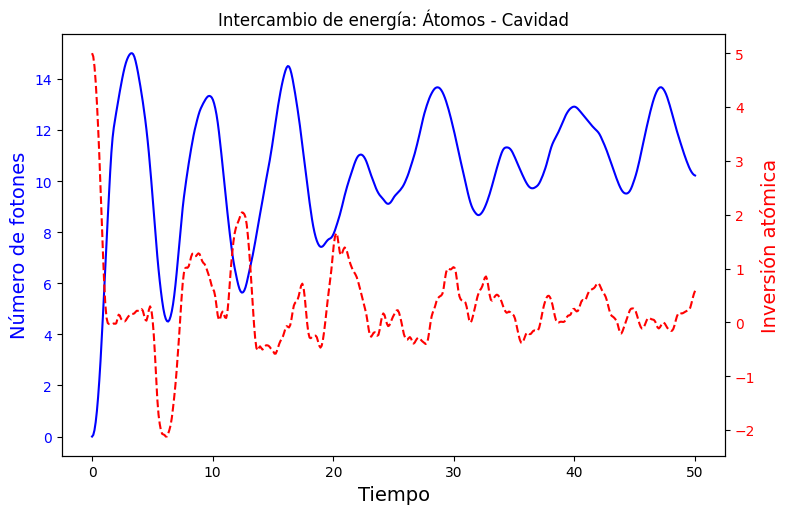

In [ ]:
H = a.dag() @ a + (epsilon/2) * J_z + (g/2) * (a  + a.dag()) * (J_p + J_m)
result = mesolve(H, rho0, tlist, c_ops=[0.05*a], e_ops=[a.dag() * a, J_z], options={"store_states": True})
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()